# 01 — From measured CALCE files to a calibration dataset

**Question:** what exactly will one objective evaluation consume?

This notebook downloads three original CALCE archives if absent, inspects the actual workbooks, and produces fixed measured traces. There is no simulated substitute. Run the installation commands in the README and select **BO vs ES (.venv)** first.

The dynamic cell is **SP20-2**; the OCV characterisation is **SP20-3** of the same model. Transferring that curve is a declared modelling assumption, not a same-cell measurement. The full protocol is [here](../docs/EXPERIMENTAL_PROTOCOL_V1.md).

Flow: original archives → channel tables → conditioning/profile separation → current sign and SOC → fixed OCV curve → model inputs and measured voltage targets.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/.matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bo_vs_es.analysis.study import save_figure
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 15)
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])


Repository: /Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary
Python: 3.13.6


/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
from bo_vs_es.objectives.data import prepare
raw, traces, ocv, audit = prepare()
display(pd.DataFrame(audit["sources"])[["file", "bytes", "sha256"]])
display(pd.DataFrame(audit["workbooks"]).T)
print("Original files stay in data/raw; processed tables and the audit are in data/processed.")

,file,bytes,sha256
0,SP2_25C_DST.zip,3189603,3d3a90a67574c336eca9d097a5f139aaad70e7fa310607...
1,SP2_25C_FUDS.zip,3426587,e2ce8e4626c4263cb8758c9488cec66d31c04a9d11465c...
2,SP3_25C_LC_OCV_11_16_2015.zip,11486330,0bae869bba13c2d87faa3ae948557c47e5b4be96b93ee4...


,workbook,sheets,input_rows,output_rows,overlapping_records_removed,repeated_timestamps_keep_last
dst80,11_05_2015_SP20-2_DST_80SOC.xls,[Channel_1-008],12561,12561,0,0
fuds80,11_06_2015_SP20-2_FUDS_80SOC.xls,[Channel_1-008],13681,13681,0,0
fuds50,11_09_2015_SP20-2_FUDS_50SOC.xls,[Channel_1-008],9308,9308,0,0
ocv,11_16_2015_low current OCV test_SP20-3.xls,"[Channel_1-004_1, Channel_1-004_2]",90915,90914,1,0


Original files stay in data/raw; processed tables and the audit are in data/processed.


## Inspect before selecting
The `.xls` filenames contain OOXML data. The loader checks the bytes and reads every `Channel` sheet with openpyxl. Overlapping record IDs must agree; conflicting records fail. Repeated timestamps keep the final record and are counted in the audit.

The raw sign convention is **positive current for charging**. Internally the model uses **positive for discharge**.

,record,time_s,step,cycle,current_charge_a,voltage_v,charge_ah,discharge_ah
0,1,60.014730,1,1,0.000000,3.938208,0.000000,0.0
1,2,70.015037,2,1,0.999834,4.020122,0.002777,0.0
2,3,80.015269,2,1,0.999834,4.025464,0.005555,0.0
3,4,90.030834,2,1,1.000014,4.029349,0.008337,0.0
4,5,100.046322,2,1,0.999834,4.032263,0.011118,0.0
5,6,110.061532,2,1,0.999834,4.034691,0.013896,0.0
6,7,120.077568,2,1,0.999834,4.036796,0.016682,0.0
7,8,130.092966,2,1,1.000014,4.038900,0.019464,0.0


,observations,start_s,end_s,current_min_a,current_max_a
step,,,,,
1,1,60.014730,60.014730,0.000000,0.000000
2,102,70.015037,1077.898926,0.999653,1.000195
3,229,1087.914915,3363.414541,0.019848,0.972381
4,720,3373.430358,10563.426986,0.000000,0.000000
5,144,10573.443198,12003.433139,-1.000414,-0.999872
6,720,12013.449463,19203.446229,0.000000,0.000000
7,10621,19204.465108,29914.676677,-4.001960,2.001132
8,24,19563.477552,29283.976536,0.000000,0.000000


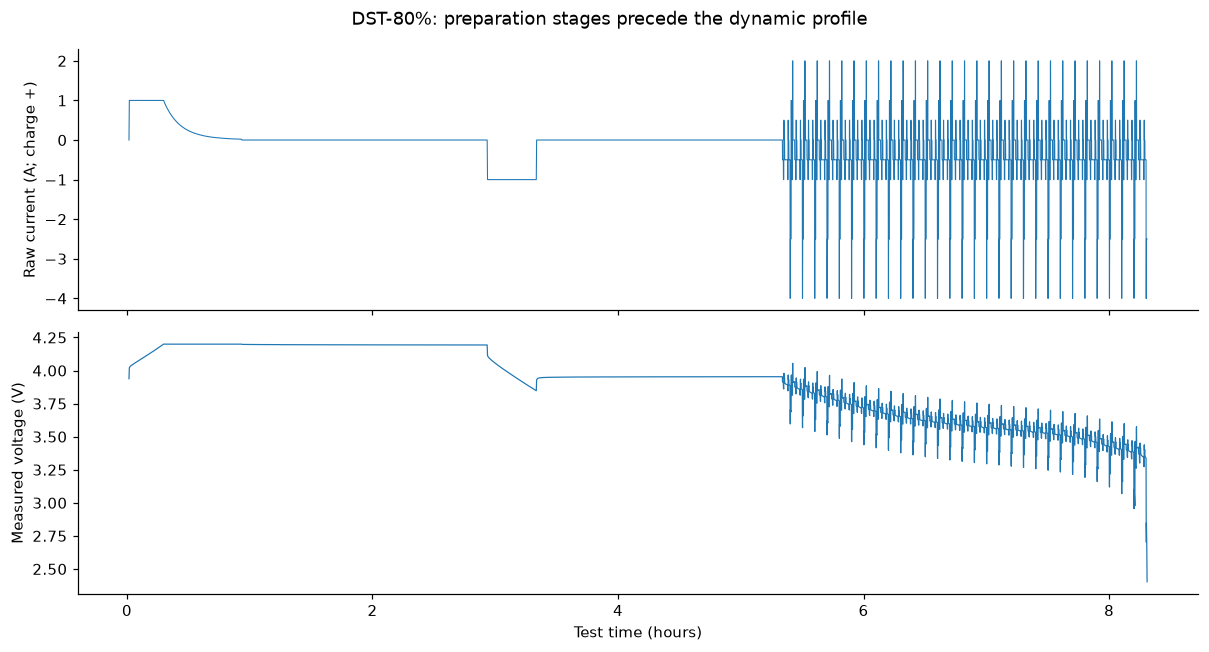

In [3]:
display(raw["dst80"].head(8))
stages = raw["dst80"].groupby("step", sort=False).agg(
    observations=("record", "size"), start_s=("time_s", "min"), end_s=("time_s", "max"),
    current_min_a=("current_charge_a", "min"), current_max_a=("current_charge_a", "max"))
display(stages)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(raw["dst80"].time_s / 3600, raw["dst80"].current_charge_a, lw=.7)
axes[0].set_ylabel("Raw current (A; charge +)")
axes[1].plot(raw["dst80"].time_s / 3600, raw["dst80"].voltage_v, lw=.8)
axes[1].set(xlabel="Test time (hours)", ylabel="Measured voltage (V)")
fig.suptitle("DST-80%: preparation stages precede the dynamic profile")
fig.tight_layout(); save_figure(fig, "data_raw_stages"); plt.show()

## Freeze the windows
Step 7 starts the dynamic profile after step-6 rest. Retain later interleaved rests, and prepend the last preparatory-rest sample as the initial state. Use the next 3,600 seconds without resampling. The model holds the left-endpoint current over each interval.

**Calibration:** DST-80%. **Assessment only:** FUDS-80% and FUDS-50%. Initial SOC is the nominal value in the experiment label; capacity is fixed at 2 Ah. SOC outside [0,1] is an error, not silently clipped. Assessment voltage is never used to select parameters.

,trace,rows,end_s,soc_min,soc_max,median_dt_s,maximum_dt_s
0,dst80,3578,3599.890761,0.530665,0.8,1.015544,1.018879
1,fuds80,3568,3599.773323,0.534703,0.8,1.015539,1.026644
2,fuds50,3568,3599.602901,0.234060,0.5,1.015412,1.065334


,time_s,current_a,soc,voltage_v,step
0,0.000000,-0.000000,0.8,3.953425,6
1,1.018879,0.000019,0.8,3.953425,7
2,2.034490,0.000019,0.8,3.953587,7
3,3.050034,0.000200,0.8,3.953587,7
4,4.065719,0.000019,0.8,3.953425,7


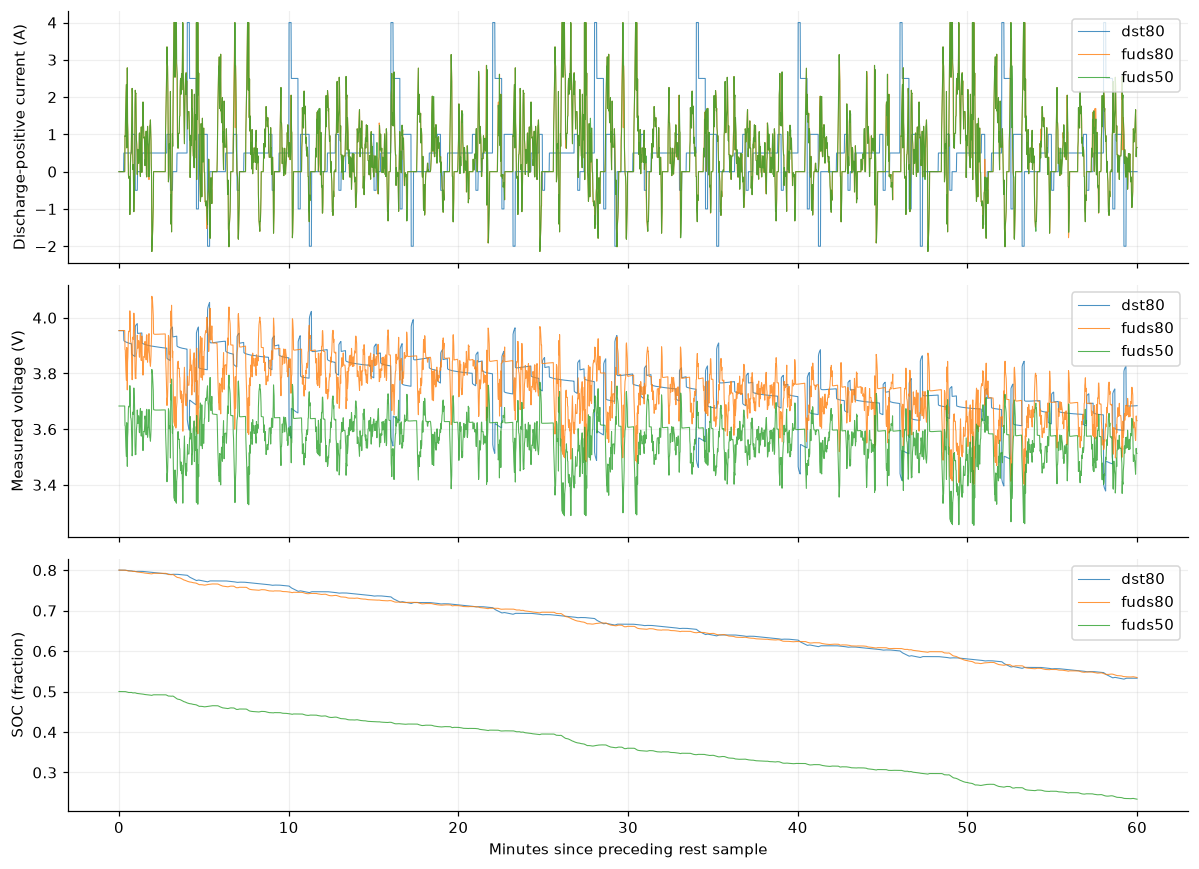

In [4]:
summary = pd.DataFrame([{"trace": k, "rows": len(t), "end_s": t.time_s.iloc[-1],
    "soc_min": t.soc.min(), "soc_max": t.soc.max(), "median_dt_s": t.time_s.diff().median(),
    "maximum_dt_s": t.time_s.diff().max()} for k,t in traces.items()])
display(summary)
display(traces["dst80"][["time_s", "current_a", "soc", "voltage_v", "step"]].head())
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for name,t in traces.items():
    for ax, column in zip(axes, ["current_a", "voltage_v", "soc"]):
        ax.plot(t.time_s / 60, t[column], label=name, alpha=.8, lw=.7)
for ax,label in zip(axes,["Discharge-positive current (A)","Measured voltage (V)","SOC (fraction)"]):
    ax.set_ylabel(label); ax.legend(); ax.grid(alpha=.2)
axes[-1].set_xlabel("Minutes since preceding rest sample")
fig.tight_layout(); save_figure(fig,"data_selected_traces"); plt.show()

## Characterisation supplied to every method
Normalise the measured low-current discharge and charge branches separately by their own capacity spans. Interpolate their voltage curves onto a common SOC grid and average them. This approximates OCV; hysteresis and inter-cell variation remain limitations.

The constant correction is the mean voltage during the final 60 seconds of the **DST preparatory rest** minus the characterisation voltage at SOC 0.8. Freeze it once and reuse it for both assessment traces. The uncorrected objective is tested separately.

discharge_ah    2.080151
charge_ah       2.019390
Name: Measured characterisation capacity span (Ah), dtype: float64

Calibration-rest offset: 12.155 mV


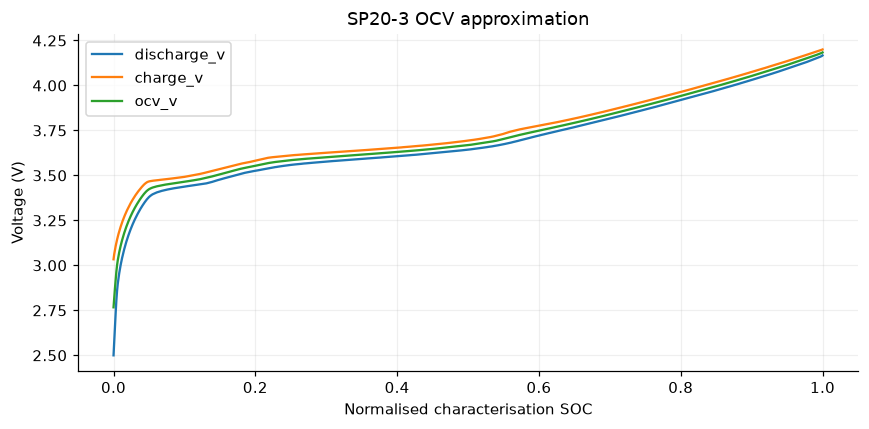

Prepared-data SHA256 checksums:


dst80.csv     71a9efd866301cf1090bbdc8ca0ae7475050fc1ad24c48...
fuds50.csv    dee9cb1b25625da9c71ab781238c4a8848caa1f72fa3e0...
fuds80.csv    4f1de37e5a4ad631a46655f784c975703fa5fdddaa319d...
ocv.csv       a984761dd01930e50415f6e96e4dc5b0b99338bdd39377...
dtype: str

In [5]:
display(pd.Series(audit["ocv_branch_capacity_ah"], name="Measured characterisation capacity span (Ah)"))
print(f"Calibration-rest offset: {1000*audit['calibration_rest_offset_v']:.3f} mV")
fig, ax = plt.subplots(figsize=(8,4))
for column in ["discharge_v", "charge_v", "ocv_v"]:
    ax.plot(ocv.soc, ocv[column], label=column)
ax.set(xlabel="Normalised characterisation SOC", ylabel="Voltage (V)", title="SP20-3 OCV approximation")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); save_figure(fig,"data_ocv"); plt.show()
assert all(t.soc.between(0,1).all() for t in traces.values())
print("Prepared-data SHA256 checksums:"); display(pd.Series(audit["output_sha256"]))

## What has and has not been established
We have inspected measured inputs and produced deterministic datasets with explicit provenance. We have not established unique physical parameter identifiability, a globally correct battery model, or a winner among optimisers. Those are examined in the next notebooks. Downloaded and processed data stay outside Git; this notebook's saved outputs expose what was actually used.